In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import joblib
import shap
from __future__ import annotations

from collections.abc import Sequence

import numpy as np
import pandas as pd

import lingam
from tigramite import data_processing as pp
from tigramite.pcmci import PCMCI
from tigramite.independence_tests.parcorr import ParCorr
from tigramite.independence_tests.robust_parcorr import RobustParCorr

import lingam

from IPython.display import display, Markdown

# Ignore all warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams.update({
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "lines.linewidth": 2.5,
})


# The whole X_test
# start_date="2023-07-11",
# end_date="2023-08-09",



start_date = "2023-08-02"
end_date = "2023-08-09"


# 11 -> 17, 18 -> 24, 25 -> 1, 2 -> 9




print("✓ Imports complete")

c:\Users\Iman\OneDrive\Desktop\Supply Chain Study\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Imports complete


In [2]:
df_features = pd.read_csv('../../data/FinalDataset/df_features.csv', index_col=0)
df_processed = pd.read_csv('../../data/FinalDataset/df_processed.csv', index_col=0)

X_train = pd.read_csv('../../data/FinalDataset/X_train.csv', index_col=0)
X_test = pd.read_csv('../../data/FinalDataset/X_test.csv', index_col=0)
y_train = pd.read_csv('../../data/FinalDataset/y_train.csv', index_col=0)
y_test = pd.read_csv('../../data/FinalDataset/y_test.csv', index_col=0)

X_train_with_date = X_train.copy()
X_test_with_date = X_test.copy()

# X_train.drop(columns=["Date"], inplace=True)
# X_test.drop(columns=["Date"], inplace=True)

In [3]:
df_processed["Sales"]

Date
2023-01-01    2642.0
2023-01-02    1070.0
2023-01-03    2355.0
2023-01-04     909.8
2023-01-05    3504.0
               ...  
2023-08-05     109.0
2023-08-06    2897.0
2023-08-07    2385.0
2023-08-08       0.0
2023-08-09       0.0
Name: Sales, Length: 9061, dtype: float64

<br> <br> <br>


## Feature Importance

In [4]:
x_y_test = pd.concat([X_test, y_test], axis=1)
x_y_test

,Date,Production,Factory_Issue,Delivery,Station,Rainfall,Sunshine,Humidity,Temperature,typical_rain_mm,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_7,Sales_lag_14,Sales_lag_21,Sales_lag_28,production_sales_ratio,delivery_sales_ratio,factory_issue_rate,inventory_proxy,interest_rate_value,stock_market_close,inflation_rate,balance_of_trade,exports,imports,currency_log_return,currency_momentum_5d,Product_AT5X5K,Product_ATN01K24P,Product_ATN02K12P,Product_ATPA1K24P,Product_ATPPCH5X5K,Product_ATWWP001K24P,Product_ATWWP002K12P,Product_EEA200G24P,Product_EEA500G12P,Product_MAC1K25P,Product_MAHS025K,Product_MAP1K25P,Product_MAPA1K24P,Product_MAR01K24P,Product_MAR02K12P,Product_MASR025K,Product_POP001L12P,Product_POP001L12P.1,Product_POP002L09P,Product_POP005L04P,Product_POP015K,Product_POP500M24P,Product_POPF01L12P,Product_POV001L24P,Product_POV002L09P,Product_POV005L04P,Product_POV500M24P,Product_SE200G24P,Product_SE500G24P,Product_SO0001L12P,Product_SO0002L09P,Product_SO0005L04P,Product_SO0500M24P,Product_SOP001L12P,Product_SOS001L12P,Product_SOS002L09P,Product_SOS003L04P,Product_SOS005L04P,Product_SOS008L02P,Product_SOS250M48P,Product_SOS500M24P,Group_A,Group_E,Group_M,Group_P,Group_S,Group_nan,Sub-Group_AT,Sub-Group_ATN,Sub-Group_ATPA,Sub-Group_ATPPCH,Sub-Group_ATWWP,Sub-Group_EEA,Sub-Group_MAC,Sub-Group_MAHS,Sub-Group_MAP,Sub-Group_MAPA,Sub-Group_MAR,Sub-Group_MASR,Sub-Group_POP,Sub-Group_POPF,Sub-Group_POV,Sub-Group_SE,Sub-Group_SO,Sub-Group_SOP,Sub-Group_SOS,Sub-Group_nan,holiday_type_National Holiday,holiday_type_Not a National Holiday,holiday_type_nan,holiday_name_Ashura,holiday_name_Bank Holiday,holiday_name_Bengali New Year,holiday_name_Buddha Purnima,holiday_name_Eid al-Fitr,holiday_name_Eid-ul-Azha,holiday_name_Independence Day,holiday_name_Jumatul Bidah,holiday_name_Language Mother Day,holiday_name_May Day,holiday_name_Shab e-barat,holiday_name_Shab-e-Qadr,holiday_name_Sheikh Mujibur Rahman's birthday,holiday_name_nan,category_bank_holiday,category_cultural_event,category_cultural_holiday,category_national_holiday,category_no_event,category_religious_holiday,category_religious_period,category_school_university,category_weather_event,scope_or_location_Chattogram division & south-east,scope_or_location_Nationwide,scope_or_location_Nationwide (strongest in Buddhist communities),scope_or_location_Nationwide (strongest in cities),scope_or_location_Tongi near Dhaka,scope_or_location_Urban centres (esp. Dhaka),scope_or_location_nan,Sales
191,2023-07-11,0.053025,0.074017,0.057634,Dhaka,0.026087,0.000000,0.698413,0.821256,0.000000,0.040648,0.071895,0.002373,0.031725,0.003897,0.023931,0.001197,4.219409e+00,4.502954e+00,1.452000,0.589769,0.0,0.791970,0.817518,0.000000,1.00000,1.00000,0.598798,0.719193,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,237.0
192,2023-07-12,0.053025,0.037468,0.025328,Dhaka,0.000000,0.009524,0.698413,0.811594,0.000000,0.008102,0.040648,0.071895,0.013777,0.000000,0.024785,0.034358,1.972387e+00,9.250493e-01,0.735000,0.594371,0.0,0.838398,0.817518,0.000000,1.00000,1.00000,0.563015,0.716944,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,507.0
193,2023-07-13,0.042420,0.015803,0.027650,Dhaka,0.008696,0.371429,0.714286,0.816425,0.000000,0.017333,0.008102,0.040648,0.042665,0.000000,0.034118,0.040648,7.662835e-01,4.904215

In [5]:
# load the ML model
model = joblib.load('../../models/CatBoost.pkl')
print("✓ Model loaded successfully")
print(type(model))

✓ Model loaded successfully
<class 'catboost.core.CatBoostRegressor'>


In [6]:
def get_examples_by_date(
    data,
    start_date,
    end_date,
    date_column="Date",
    target_column="Sales",
    drop_columns=("Station",),
    product=None,
):
    """Select the rows of a test frame that fall inside a date window, in temporal order.

    Unlike `.sample()`, this keeps the time ordering intact, which the causal
    methods (VARLiNGAM / PCMCI) rely on.

    data          : frame holding both features and the target (e.g. x_y_test)
    start_date    : first date to keep, inclusive ('2023-07-11', datetime, ...)
    end_date      : last date to keep, inclusive
    date_column   : column holding the timestamps
    target_column : column holding the target
    drop_columns  : extra columns to keep out of X (the target is always dropped)
    product       : optional product code, e.g. 'SOS001L12P'. Keeps only the rows of
                    that product's series, so there is exactly one row per date.

    Returns (window, X, y):
      window : the selected rows, sorted by date, index reset to 0..n-1 so the
               index is monotonic increasing as PCMCI requires
      X      : window without the target and `drop_columns`
      y      : the target Series
    """
    if date_column not in data.columns:
        raise KeyError(f"'{date_column}' is not a column of data.")
    if target_column not in data.columns:
        raise KeyError(f"'{target_column}' is not a column of data.")

    start = pd.to_datetime(start_date)
    end = pd.to_datetime(end_date)
    if start > end:
        raise ValueError(f"start_date ({start.date()}) is after end_date ({end.date()}).")

    dates = pd.to_datetime(data[date_column])
    window = data.loc[dates.between(start, end)].copy()

    if product is not None:
        product_column = product if product.startswith("Product_") else f"Product_{product}"
        if product_column not in window.columns:
            raise KeyError(f"'{product_column}' is not a column of data.")
        window = window.loc[window[product_column] == 1]

    if window.empty:
        available = f"{dates.min().date()} .. {dates.max().date()}"
        raise ValueError(
            f"No rows between {start.date()} and {end.date()}. "
            f"Available range: {available}."
        )

    # Sort on the parsed dates (kind='stable' keeps the original row order within a day),
    # then reset so the index itself is chronological.
    window = window.sort_values(date_column, kind="stable").reset_index(drop=True)

    X = window.drop(columns=[target_column, *drop_columns], errors="ignore")
    y = window[target_column]

    return window, X, y


In [7]:
# start_date = "2023-07-11"
# end_date = "2023-07-25"


# the whole test set
date_example, X_date_example, y_date_example = get_examples_by_date(
    x_y_test,
    start_date=start_date,
    end_date=end_date,
)


print(f"{len(date_example)} rows | {date_example['Date'].min()} -> {date_example['Date'].max()}")
display(X_date_example)
display(y_date_example)

328 rows | 2023-08-02 -> 2023-08-09


,Date,Production,Factory_Issue,Delivery,Rainfall,Sunshine,Humidity,Temperature,typical_rain_mm,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_7,Sales_lag_14,Sales_lag_21,Sales_lag_28,production_sales_ratio,delivery_sales_ratio,factory_issue_rate,inventory_proxy,interest_rate_value,stock_market_close,inflation_rate,balance_of_trade,exports,imports,currency_log_return,currency_momentum_5d,Product_AT5X5K,Product_ATN01K24P,Product_ATN02K12P,Product_ATPA1K24P,Product_ATPPCH5X5K,Product_ATWWP001K24P,Product_ATWWP002K12P,Product_EEA200G24P,Product_EEA500G12P,Product_MAC1K25P,Product_MAHS025K,Product_MAP1K25P,Product_MAPA1K24P,Product_MAR01K24P,Product_MAR02K12P,Product_MASR025K,Product_POP001L12P,Product_POP001L12P.1,Product_POP002L09P,Product_POP005L04P,Product_POP015K,Product_POP500M24P,Product_POPF01L12P,Product_POV001L24P,Product_POV002L09P,Product_POV005L04P,Product_POV500M24P,Product_SE200G24P,Product_SE500G24P,Product_SO0001L12P,Product_SO0002L09P,Product_SO0005L04P,Product_SO0500M24P,Product_SOP001L12P,Product_SOS001L12P,Product_SOS002L09P,Product_SOS003L04P,Product_SOS005L04P,Product_SOS008L02P,Product_SOS250M48P,Product_SOS500M24P,Group_A,Group_E,Group_M,Group_P,Group_S,Group_nan,Sub-Group_AT,Sub-Group_ATN,Sub-Group_ATPA,Sub-Group_ATPPCH,Sub-Group_ATWWP,Sub-Group_EEA,Sub-Group_MAC,Sub-Group_MAHS,Sub-Group_MAP,Sub-Group_MAPA,Sub-Group_MAR,Sub-Group_MASR,Sub-Group_POP,Sub-Group_POPF,Sub-Group_POV,Sub-Group_SE,Sub-Group_SO,Sub-Group_SOP,Sub-Group_SOS,Sub-Group_nan,holiday_type_National Holiday,holiday_type_Not a National Holiday,holiday_type_nan,holiday_name_Ashura,holiday_name_Bank Holiday,holiday_name_Bengali New Year,holiday_name_Buddha Purnima,holiday_name_Eid al-Fitr,holiday_name_Eid-ul-Azha,holiday_name_Independence Day,holiday_name_Jumatul Bidah,holiday_name_Language Mother Day,holiday_name_May Day,holiday_name_Shab e-barat,holiday_name_Shab-e-Qadr,holiday_name_Sheikh Mujibur Rahman's birthday,holiday_name_nan,category_bank_holiday,category_cultural_event,category_cultural_holiday,category_national_holiday,category_no_event,category_religious_holiday,category_religious_period,category_school_university,category_weather_event,scope_or_location_Chattogram division & south-east,scope_or_location_Nationwide,scope_or_location_Nationwide (strongest in Buddhist communities),scope_or_location_Nationwide (strongest in cities),scope_or_location_Tongi near Dhaka,scope_or_location_Urban centres (esp. Dhaka),scope_or_location_nan
0,2023-08-02,0.0,0.044094,0.036723,0.043478,0.019048,0.888889,0.724638,0.0,0.020348,0.009983,0.021127,0.017128,0.047246,0.017333,0.013777,0.0,1.877416,8.650000e+08,0.598153,0.0,0.871162,0.985401,0.361299,0.93115,0.70498,0.715504,0.805535,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2023-08-02,0.0,0.138298,0.196198,0.043478,0.019048,0.888889,0.724638,0.0,0.119809,0.096915,0.107258,0.184199,0.187395,0.096270,0.156489,0.0,2.083587,2.713000e+09,0.423513,0.0,0.871162,0.985401,0.361299,0.93115,0.70498,0.715504,0.805535,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2023-08-02,0.0,0.031809,0.055085,0.043478,0.019048,0.888889,0.724638,0.0,0.030164,0.012772,0.020145,0.023264,0.025013,0.033349,0.020663,0.0,1.601675,6.240000e+08,0.569964,0.0,0.871162,0.985401,0.361299,0.93115,0.70498,0.715504,0.805535,0.0,0.0,1.0,0.0,0.0

0       362.200000
1      1743.628000
2       636.833333
3         0.000000
4         0.000000
          ...     
323       0.000000
324       0.000000
325       0.000000
326       0.000000
327       0.000000
Name: Sales, Length: 328, dtype: float64

<br> <br> <br>

# Feature Importance

328 rows | 2023-08-02 -> 2023-08-09


,Date,Production,Factory_Issue,Delivery,Rainfall,Sunshine,Humidity,Temperature,typical_rain_mm,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_7,Sales_lag_14,Sales_lag_21,Sales_lag_28,production_sales_ratio,delivery_sales_ratio,factory_issue_rate,inventory_proxy,interest_rate_value,stock_market_close,inflation_rate,balance_of_trade,exports,imports,currency_log_return,currency_momentum_5d,Product_AT5X5K,Product_ATN01K24P,Product_ATN02K12P,Product_ATPA1K24P,Product_ATPPCH5X5K,Product_ATWWP001K24P,Product_ATWWP002K12P,Product_EEA200G24P,Product_EEA500G12P,Product_MAC1K25P,Product_MAHS025K,Product_MAP1K25P,Product_MAPA1K24P,Product_MAR01K24P,Product_MAR02K12P,Product_MASR025K,Product_POP001L12P,Product_POP001L12P.1,Product_POP002L09P,Product_POP005L04P,Product_POP015K,Product_POP500M24P,Product_POPF01L12P,Product_POV001L24P,Product_POV002L09P,Product_POV005L04P,Product_POV500M24P,Product_SE200G24P,Product_SE500G24P,Product_SO0001L12P,Product_SO0002L09P,Product_SO0005L04P,Product_SO0500M24P,Product_SOP001L12P,Product_SOS001L12P,Product_SOS002L09P,Product_SOS003L04P,Product_SOS005L04P,Product_SOS008L02P,Product_SOS250M48P,Product_SOS500M24P,Group_A,Group_E,Group_M,Group_P,Group_S,Group_nan,Sub-Group_AT,Sub-Group_ATN,Sub-Group_ATPA,Sub-Group_ATPPCH,Sub-Group_ATWWP,Sub-Group_EEA,Sub-Group_MAC,Sub-Group_MAHS,Sub-Group_MAP,Sub-Group_MAPA,Sub-Group_MAR,Sub-Group_MASR,Sub-Group_POP,Sub-Group_POPF,Sub-Group_POV,Sub-Group_SE,Sub-Group_SO,Sub-Group_SOP,Sub-Group_SOS,Sub-Group_nan,holiday_type_National Holiday,holiday_type_Not a National Holiday,holiday_type_nan,holiday_name_Ashura,holiday_name_Bank Holiday,holiday_name_Bengali New Year,holiday_name_Buddha Purnima,holiday_name_Eid al-Fitr,holiday_name_Eid-ul-Azha,holiday_name_Independence Day,holiday_name_Jumatul Bidah,holiday_name_Language Mother Day,holiday_name_May Day,holiday_name_Shab e-barat,holiday_name_Shab-e-Qadr,holiday_name_Sheikh Mujibur Rahman's birthday,holiday_name_nan,category_bank_holiday,category_cultural_event,category_cultural_holiday,category_national_holiday,category_no_event,category_religious_holiday,category_religious_period,category_school_university,category_weather_event,scope_or_location_Chattogram division & south-east,scope_or_location_Nationwide,scope_or_location_Nationwide (strongest in Buddhist communities),scope_or_location_Nationwide (strongest in cities),scope_or_location_Tongi near Dhaka,scope_or_location_Urban centres (esp. Dhaka),scope_or_location_nan
0,2023-08-02,0.0,0.044094,0.036723,0.043478,0.019048,0.888889,0.724638,0.0,0.020348,0.009983,0.021127,0.017128,0.047246,0.017333,0.013777,0.0,1.877416,8.650000e+08,0.598153,0.0,0.871162,0.985401,0.361299,0.93115,0.70498,0.715504,0.805535,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2023-08-02,0.0,0.138298,0.196198,0.043478,0.019048,0.888889,0.724638,0.0,0.119809,0.096915,0.107258,0.184199,0.187395,0.096270,0.156489,0.0,2.083587,2.713000e+09,0.423513,0.0,0.871162,0.985401,0.361299,0.93115,0.70498,0.715504,0.805535,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2023-08-02,0.0,0.031809,0.055085,0.043478,0.019048,0.888889,0.724638,0.0,0.030164,0.012772,0.020145,0.023264,0.025013,0.033349,0.020663,0.0,1.601675,6.240000e+08,0.569964,0.0,0.871162,0.985401,0.361299,0.93115,0.70498,0.715504,0.805535,0.0,0.0,1.0,0.0,0.0

0       362.200000
1      1743.628000
2       636.833333
3         0.000000
4         0.000000
          ...     
323       0.000000
324       0.000000
325       0.000000
326       0.000000
327       0.000000
Name: Sales, Length: 328, dtype: float64

Saved plot -> ..\..\feature_importance\feature_importance_2023-08-02_2023-08-09\SHAP_top_20_from_2023-08-02_to_2023-08-09.png


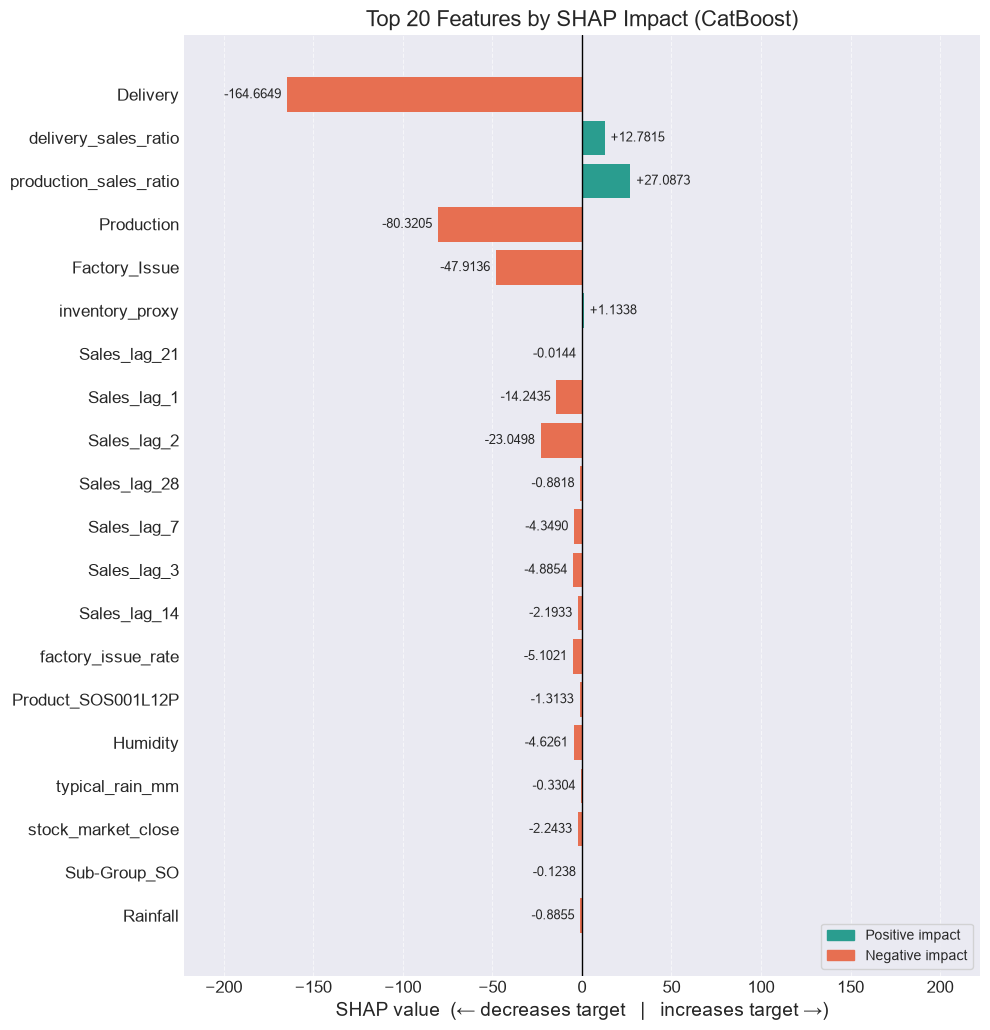

,Feature name,feature importance,shap_signed,direction
0,Delivery,700.779332,-164.664909,negative
1,delivery_sales_ratio,556.669952,12.781453,positive
2,production_sales_ratio,142.800837,27.087321,positive
3,Production,134.727743,-80.320533,negative
4,Factory_Issue,126.131733,-47.913589,negative
5,inventory_proxy,71.704255,1.133798,positive
6,Sales_lag_21,54.339930,-0.014386,negative
7,Sales_lag_1,52.238040,-14.243520,negative
8,Sales_lag_2,51.604768,-23.049834,negative
9,Sales_lag_28,47.608112,-0.881832,negative


In [8]:
from pathlib import Path


def get_top_shap_features(model, X, y=None, top_n=10):
    """Rank features by mean |SHAP| while preserving the signed contribution.

    Returns a DataFrame with:
      - 'feature importance' : mean(|SHAP|)  -> magnitude of influence
      - 'shap_signed'        : mean(SHAP)    -> direction (+ pushes target up, - pushes it down)
      - 'direction'          : 'positive' / 'negative'
    """
    explanation = shap.Explainer(model)(X)
    shap_values = explanation.values

    signed = shap_values.mean(axis=0)

    out = pd.DataFrame({
        "Feature name": X.columns,
        "feature importance": np.abs(shap_values).mean(axis=0),
        "shap_signed": signed,
        "direction": np.where(signed >= 0, "positive", "negative"),
    })

    return (
        out.sort_values("feature importance", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )


def plot_shap_feature_importance(importance_df, title="Top SHAP Feature Importance", save_path=None):
    """Signed SHAP bar chart: bars extend left (negative) or right (positive) of zero.

    save_path : optional file to write the figure to. Saved before `plt.show()`,
                since the inline backend detaches the figure once it is displayed.
    """
    plot_df = importance_df.sort_values("feature importance", ascending=True)

    pos_color, neg_color = "#2a9d8f", "#e76f51"
    colors = [neg_color if v < 0 else pos_color for v in plot_df["shap_signed"]]

    fig, ax = plt.subplots(figsize=(10, 0.42 * len(plot_df) + 2))
    bars = ax.barh(plot_df["Feature name"], plot_df["shap_signed"], color=colors)

    ax.axvline(0, color="black", linewidth=1)
    ax.set_xlabel("SHAP value  (← decreases target   |   increases target →)")
    ax.set_ylabel("")
    ax.set_title(title)
    ax.grid(axis="x", linestyle="--", alpha=0.6)
    ax.grid(axis="y", visible=False)
    ax.spines[["top", "right", "left"]].set_visible(False)

    span = np.abs(plot_df["shap_signed"]).max()
    for bar, value in zip(bars, plot_df["shap_signed"]):
        offset = span * 0.02
        ax.text(
            value + (offset if value >= 0 else -offset),
            bar.get_y() + bar.get_height() / 2,
            f"{value:+.4f}",
            va="center",
            ha="left" if value >= 0 else "right",
            fontsize=9,
        )
    ax.set_xlim(-span * 1.35, span * 1.35)

    handles = [
        plt.Rectangle((0, 0), 1, 1, color=pos_color),
        plt.Rectangle((0, 0), 1, 1, color=neg_color),
    ]
    ax.legend(handles, ["Positive impact", "Negative impact"], loc="lower right", frameon=True)

    plt.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Saved plot -> {save_path}")

    plt.show()
    return fig


date_example, X_date_example, y_date_example = get_examples_by_date(
    data = x_y_test, 
    start_date= start_date, 
    end_date=end_date, 
    # product="SOS001L12P"
)

print(f"{len(date_example)} rows | {date_example['Date'].min()} -> {date_example['Date'].max()}")
display(X_date_example)
display(y_date_example)

top_n = 20

shap_feature_importance = get_top_shap_features(model, X_date_example.drop(columns=["Date"]), y_date_example, top_n=top_n)


fi_dir = Path(f"../../feature_importance/feature_importance_{start_date}_{end_date}")
fi_dir.mkdir(parents=True, exist_ok=True)


shap_plot_path = f"{fi_dir}/SHAP_top_{top_n}_from_{start_date}_to_{end_date}.png"

shap_fig = plot_shap_feature_importance(
    shap_feature_importance,
    title=f"Top {len(shap_feature_importance)} Features by SHAP Impact (CatBoost)",
    save_path=shap_plot_path,
)
display(shap_feature_importance)

In [9]:
# Features that push the prediction DOWN, strongest suppressor first
negative_features = (
    shap_feature_importance
    .query("shap_signed < 0")
    .sort_values("shap_signed")          # most negative at the top
    .reset_index(drop=True)
)

# Features that push the prediction UP
positive_features = (
    shap_feature_importance
    .query("shap_signed > 0")
    .sort_values("shap_signed", ascending=False)
    .reset_index(drop=True)
)

print(f"Negative impact: {len(negative_features)} | Positive impact: {len(positive_features)}")
display(Markdown("### ⬇️ Features decreasing Sales"))
display(negative_features)
display(Markdown("### ⬆️ Features increasing Sales"))
display(positive_features)


Negative impact: 17 | Positive impact: 3


### ⬇️ Features decreasing Sales

,Feature name,feature importance,shap_signed,direction
0,Delivery,700.779332,-164.664909,negative
1,Production,134.727743,-80.320533,negative
2,Factory_Issue,126.131733,-47.913589,negative
3,Sales_lag_2,51.604768,-23.049834,negative
4,Sales_lag_1,52.238040,-14.243520,negative
5,factory_issue_rate,14.197664,-5.102071,negative
6,Sales_lag_3,29.159099,-4.885381,negative
7,Humidity,5.725765,-4.626092,negative
8,Sales_lag_7,45.183196,-4.348994,negative
9,stock_market_close,4.570542,-2.243342,negative


### ⬆️ Features increasing Sales

,Feature name,feature importance,shap_signed,direction
0,production_sales_ratio,142.800837,27.087321,positive
1,delivery_sales_ratio,556.669952,12.781453,positive
2,inventory_proxy,71.704255,1.133798,positive


<br> <br> <br>

# Causal Analysis

In [10]:
cols = shap_feature_importance["Feature name"].to_list()
display(date_example[cols])
display(date_example["Sales"])

,Delivery,delivery_sales_ratio,production_sales_ratio,Production,Factory_Issue,inventory_proxy,Sales_lag_21,Sales_lag_1,Sales_lag_2,Sales_lag_28,Sales_lag_7,Sales_lag_3,Sales_lag_14,factory_issue_rate,Product_SOS001L12P,Humidity,typical_rain_mm,stock_market_close,Sub-Group_SO,Rainfall
0,0.036723,1.877416,0.0,0.0,0.044094,0.598153,0.017333,0.020348,0.009983,0.013777,0.017128,0.021127,0.047246,8.650000e+08,0.0,0.888889,0.0,0.871162,0.0,0.043478
1,0.196198,2.083587,0.0,0.0,0.138298,0.423513,0.096270,0.119809,0.096915,0.156489,0.184199,0.107258,0.187395,2.713000e+09,0.0,0.888889,0.0,0.871162,0.0,0.043478
2,0.055085,1.601675,0.0,0.0,0.031809,0.569964,0.033349,0.030164,0.012772,0.020663,0.023264,0.020145,0.025013,6.240000e+08,0.0,0.888889,0.0,0.871162,0.0,0.043478
3,0.000000,0.000000,0.0,0.0,0.000000,0.631563,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.888889,0.0,0.871162,0.0,0.043478
4,0.000000,0.000000,0.0,0.0,0.000000,0.631759,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.888889,0.0,0.871162,0.0,0.043478
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
323,0.000000,0.000000,0.0,0.0,0.000000,0.610428,0.033879,0.000000,0.019110,0.039315,0.031153,0.039007,0.053400,0.000000e+00,0.0,0.825397,0.0,0.628416,0.0,0.060870
324,0.000000,0.000000,0.0,0.0,0.000000,0.267166,0.218352,0.000000,0.176814,0.315647,0.148798,0.255308,0.255444,0.000000e+00,0.0,0.825397,0.0,0.628416,0.0,0.060870
325,0.000000,0.000000,0.0,0.0,0.000000,0.596774,0.014837,0.000000,0.007863,0.014495,0.019521,0.045161,0.005299,0.000000e+00,0.0,0.825397,0.0,0.628416,0.0,0.060870
326,0.000000,0.000000,0.0,0.0,0.000000,0.656448,0.012649,0.000000,0.015965,0.002154,0.009470,0.015829,0.011350,0.000000e+00,0.0,0.825397,0.0,0.628416,0.0,0.060870


0       362.200000
1      1743.628000
2       636.833333
3         0.000000
4         0.000000
          ...     
323       0.000000
324       0.000000
325       0.000000
326       0.000000
327       0.000000
Name: Sales, Length: 328, dtype: float64

In [11]:
def get_causal_edges(
    feature_data,
    target,
    lag=2,
    target_name="Sales",
    target_only=True,
    include_target_history=True,
    min_abs=0.0,
    include_isolated=True,
    standardize=False,
):
    """Fit VARLiNGAM on features + target and return the causal links it finds.

    feature_data           : numeric time series of features, one row per time step,
                             already sorted by date
    target                 : the target Series (same index as feature_data)
    lag                    : how many past time steps the model may look back at
    target_name            : name the target gets inside the causal graph
    target_only            : keep only the edges that point INTO the target
                             (i.e. feature -> target); set False to get the full graph
                             of every variable on every other variable
    include_target_history : keep target(t-k) -> target(t) autoregressive edges
    min_abs                : drop links weaker than this. VARLiNGAM returns a dense
                             matrix in which most entries are numerical dust
                             (often < 1e-10), so a threshold is usually needed
    include_isolated       : when the full graph is requested, also list the variables
                             left with no surviving link, as rows with no effect and a
                             zero coefficient, so the whole variable set is visible
    standardize            : z-score every variable before fitting. VARLiNGAM
                             coefficients are unstandardised, so on raw data a link
                             out of Sales (thousands) dwarfs one out of a rate (~0.01)
                             purely because of units. Standardising puts every
                             coefficient in standard-deviation units, which is what
                             makes edges comparable across different pairs

    Returns one row per edge:
      - 'cause'       : node the arrow starts from
      - 'effect'      : node the arrow points to (NaN for an isolated variable)
      - 'lag'         : 0 = same time step, k = the cause happened k steps earlier
      - 'coefficient' : strength of the link
      - 'direction'   : 'positive' (cause raises effect) / 'negative' (cause lowers
                        effect) / 'none' (isolated variable)

    The full list of modelled variables is kept on `.attrs["variables"]`, and any
    variable dropped before fitting on `.attrs["dropped"]`.
    """
    if not isinstance(feature_data, pd.DataFrame):
        raise TypeError("feature_data must be a pandas DataFrame.")
    if not isinstance(target, pd.Series):
        raise TypeError("target must be a pandas Series.")
    if target_name in feature_data.columns:
        raise ValueError(
            f"target_name='{target_name}' is already a column in feature_data."
        )

    # Put the target in the same table as the features: VARLiNGAM estimates one
    # joint graph over all columns, so the target has to be a node in it.
    data = feature_data.join(target.rename(target_name), how="inner")
    if data.empty:
        raise ValueError("No overlapping rows between feature_data and target.")

    offered = list(data.columns)
    data = data.select_dtypes(include="number").ffill().bfill()
    data = data.loc[:, data.std() > 0]          # constant columns carry no information
    dropped = [column for column in offered if column not in data.columns]

    if target_name not in data.columns:
        raise ValueError(f"'{target_name}' is constant or non-numeric after cleaning.")

    if standardize:
        data = (data - data.mean()) / data.std()

    model = lingam.VARLiNGAM(lags=lag, criterion=None)
    model.fit(data.values)

    edges = []
    # adjacency_matrices_[k][effect, cause] = effect of cause(t - k) on effect(t)
    for k, matrix in enumerate(model.adjacency_matrices_):
        for effect_idx, cause_idx in zip(*np.nonzero(matrix)):
            coefficient = matrix[effect_idx, cause_idx]
            if abs(coefficient) <= min_abs:
                continue
            edges.append({
                "cause": data.columns[cause_idx],
                "effect": data.columns[effect_idx],
                "lag": k,
                "coefficient": coefficient,
                "direction": "positive" if coefficient > 0 else "negative",
            })

    edges = pd.DataFrame(edges, columns=["cause", "effect", "lag", "coefficient", "direction"])

    if target_only:
        edges = edges[edges["effect"] == target_name]
        if not include_target_history:
            edges = edges[edges["cause"] != target_name]

    edges = edges.sort_values("coefficient", key=abs, ascending=False).reset_index(drop=True)

    variables = list(data.columns)
    # Only meaningful for the full graph: with target_only every variable that does not
    # cause the target would be listed as "isolated", which is a different statement.
    if include_isolated and not target_only:
        # A variable is isolated when no surviving link touches it in either role.
        linked = set(edges["cause"]) | set(edges["effect"])
        isolated = pd.DataFrame(
            [
                {"cause": name, "effect": None, "lag": pd.NA,
                 "coefficient": 0.0, "direction": "none"}
                for name in variables if name not in linked
            ],
            columns=edges.columns,
        )
        if not isolated.empty:
            edges = pd.concat([edges, isolated], ignore_index=True)

    edges["lag"] = edges["lag"].astype("Int64")
    edges.attrs["variables"] = variables
    edges.attrs["dropped"] = dropped
    return edges


cols = shap_feature_importance["Feature name"].to_list()

# causal_edges = get_causal_edges(
#     feature_data=date_example[cols],
#     target=date_example["Sales"],
#     lag=2,
#     target_name="Sales",
#     target_only=False,
# )


# causal_edges_all = get_causal_edges(
#     feature_data=date_example[cols],
#     target=date_example["Sales"],
#     lag=1,
#     target_name="Sales",
#     target_only=False,
#     standardize=True,
#     min_abs=0.05,
# )


# causal_edges_all


In [12]:
# causal_edges_all[(causal_edges_all["cause"] == "Sales") | (causal_edges_all["effect"] == "Sales")]

154 rows | 154 links | 0 variable(s) with no link


,cause,effect,lag,coefficient,direction
4,typical_rain_mm,Rainfall,0,0.960310,positive
5,Sales_lag_28,Sales_lag_7,0,0.941089,positive
6,typical_rain_mm,Rainfall,1,-0.936494,negative
7,delivery_sales_ratio,production_sales_ratio,0,0.810113,positive
8,Sales_lag_28,Sales_lag_14,0,0.773527,positive
...,...,...,...,...,...
160,Sales_lag_1,Sales_lag_3,1,-0.058062,negative
161,delivery_sales_ratio,Sales_lag_1,1,-0.058050,negative
162,Rainfall,Sales_lag_14,1,-0.055126,negative
163,Production,Sales_lag_21,0,-0.055046,negative


Saved plot -> ..\..\causality\causality_2023-08-02_2023-08-09\causal_matrix_lag1_from_2023-08-02_to_2023-08-09.png


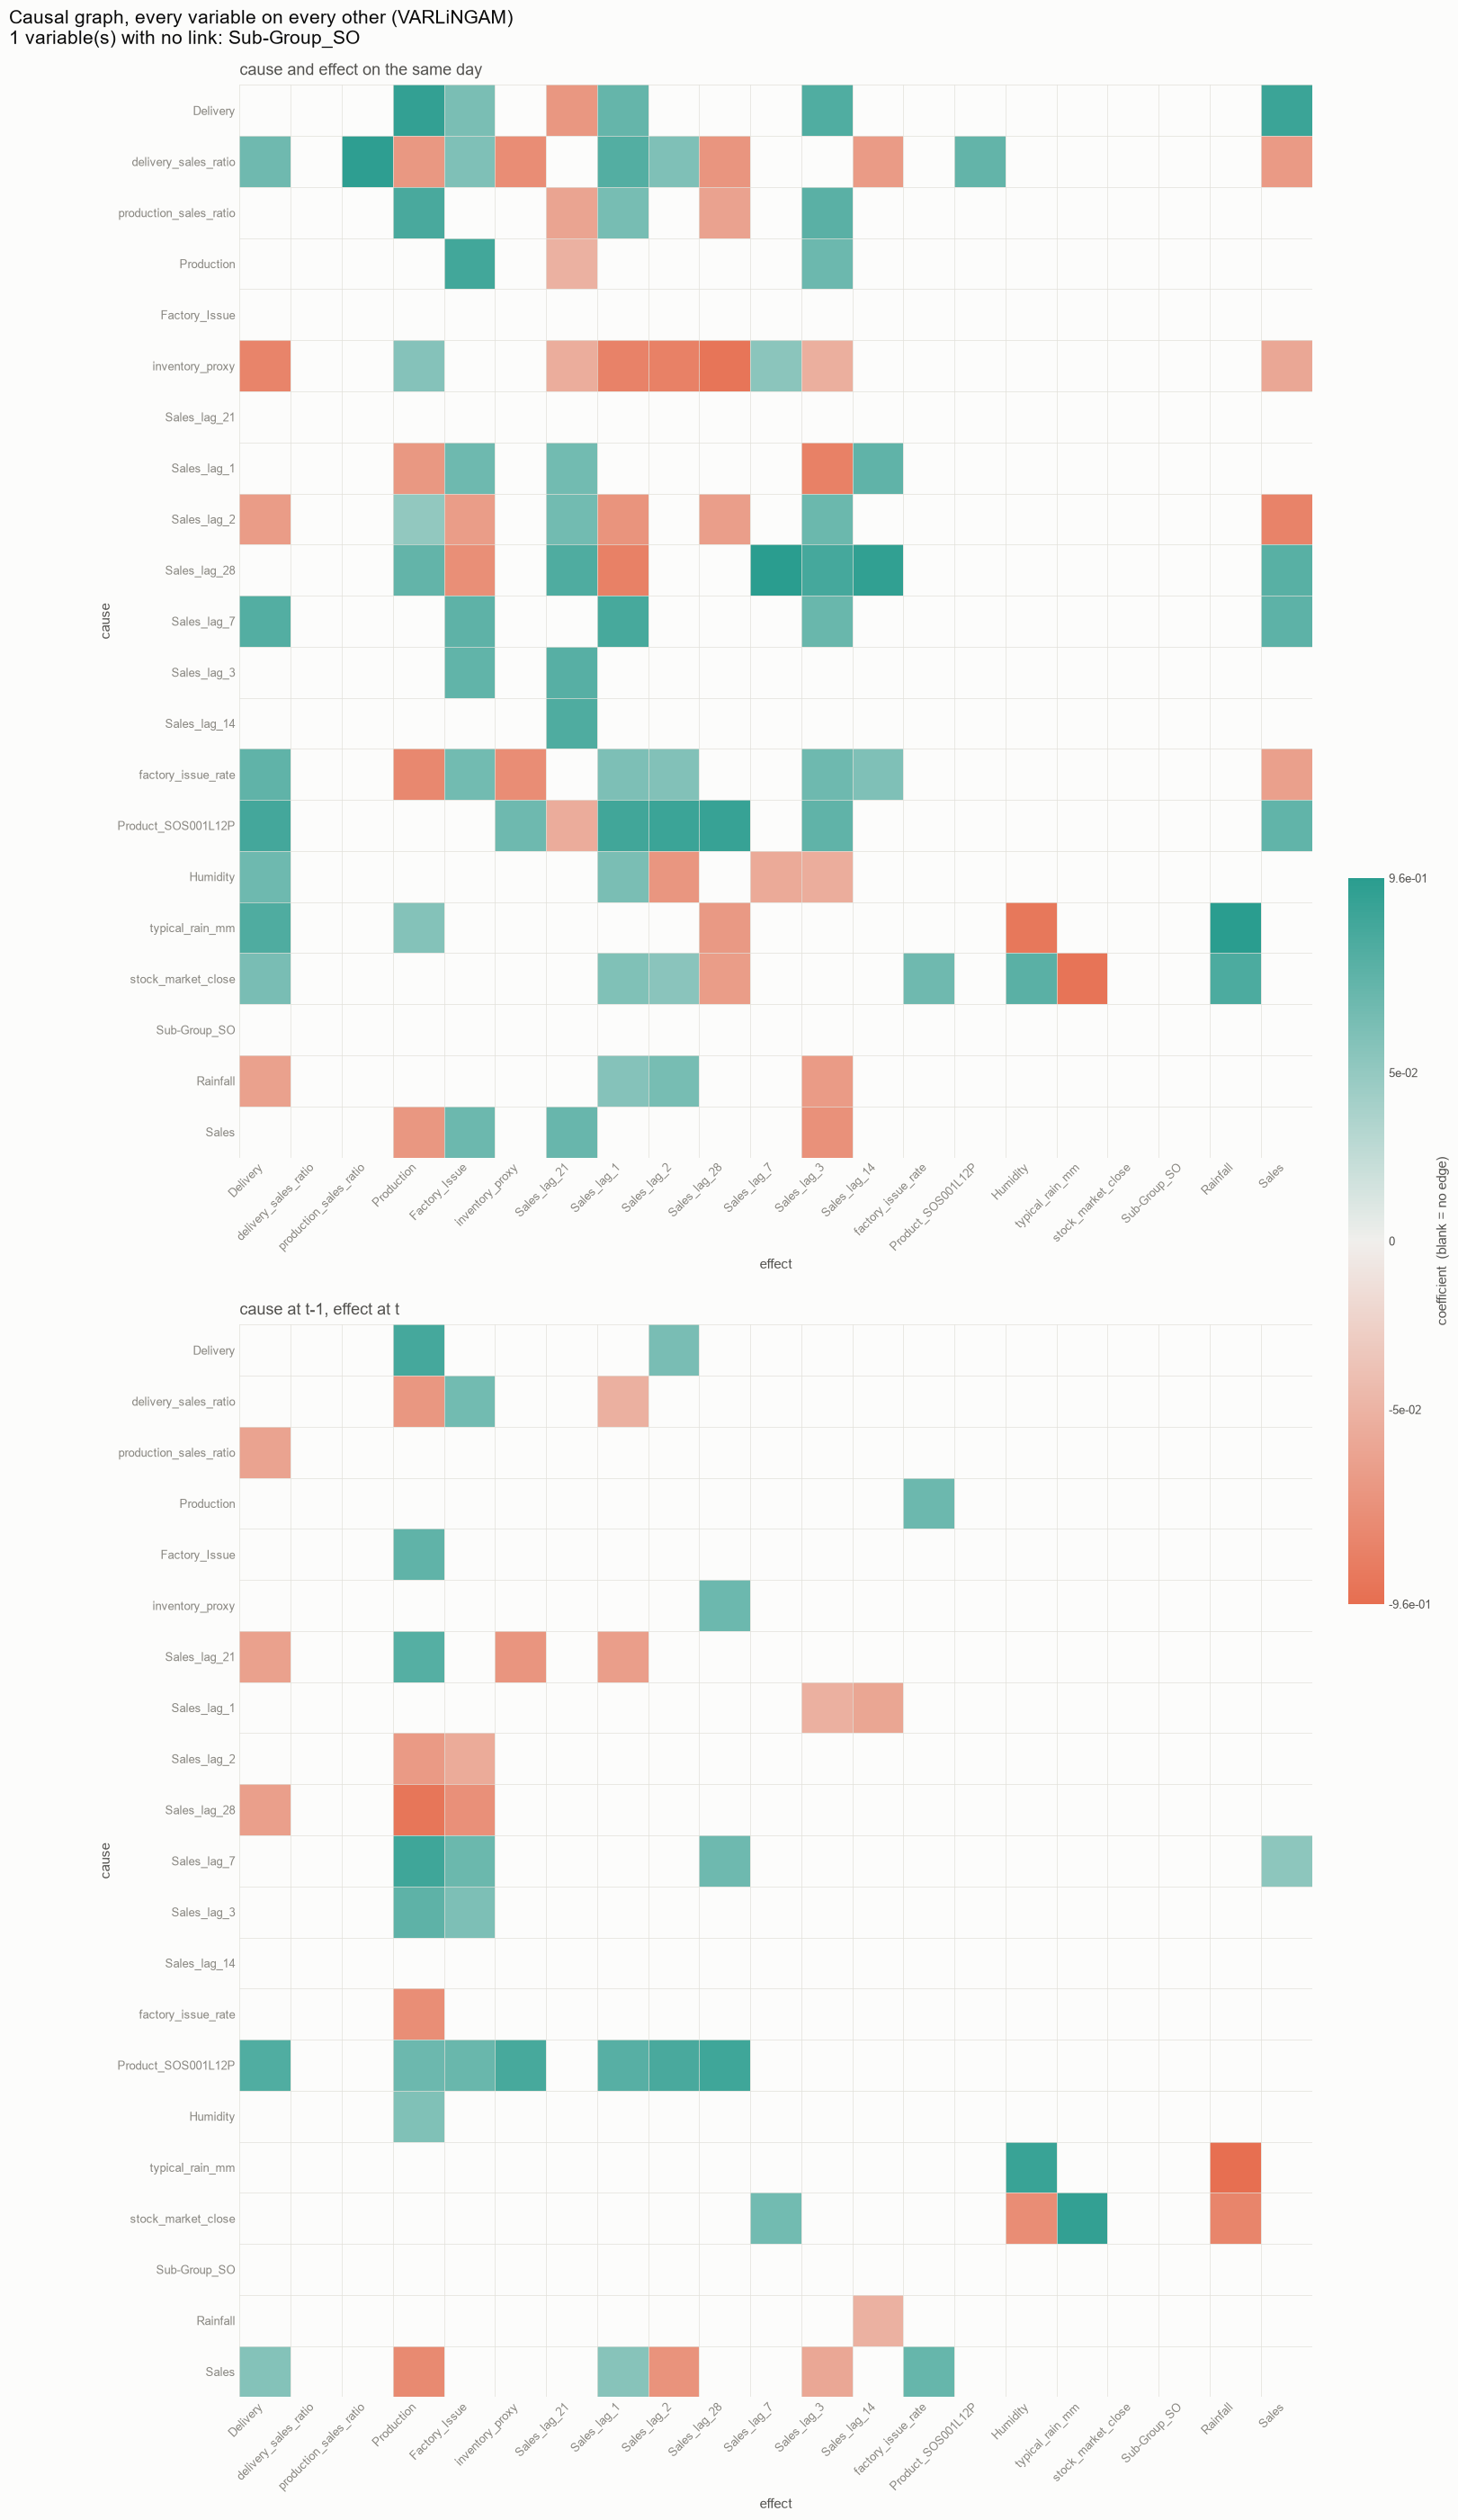

Saved plot -> ..\..\causality\causality_2023-08-02_2023-08-09\causal_network_lag1_from_2023-08-02_to_2023-08-09.png


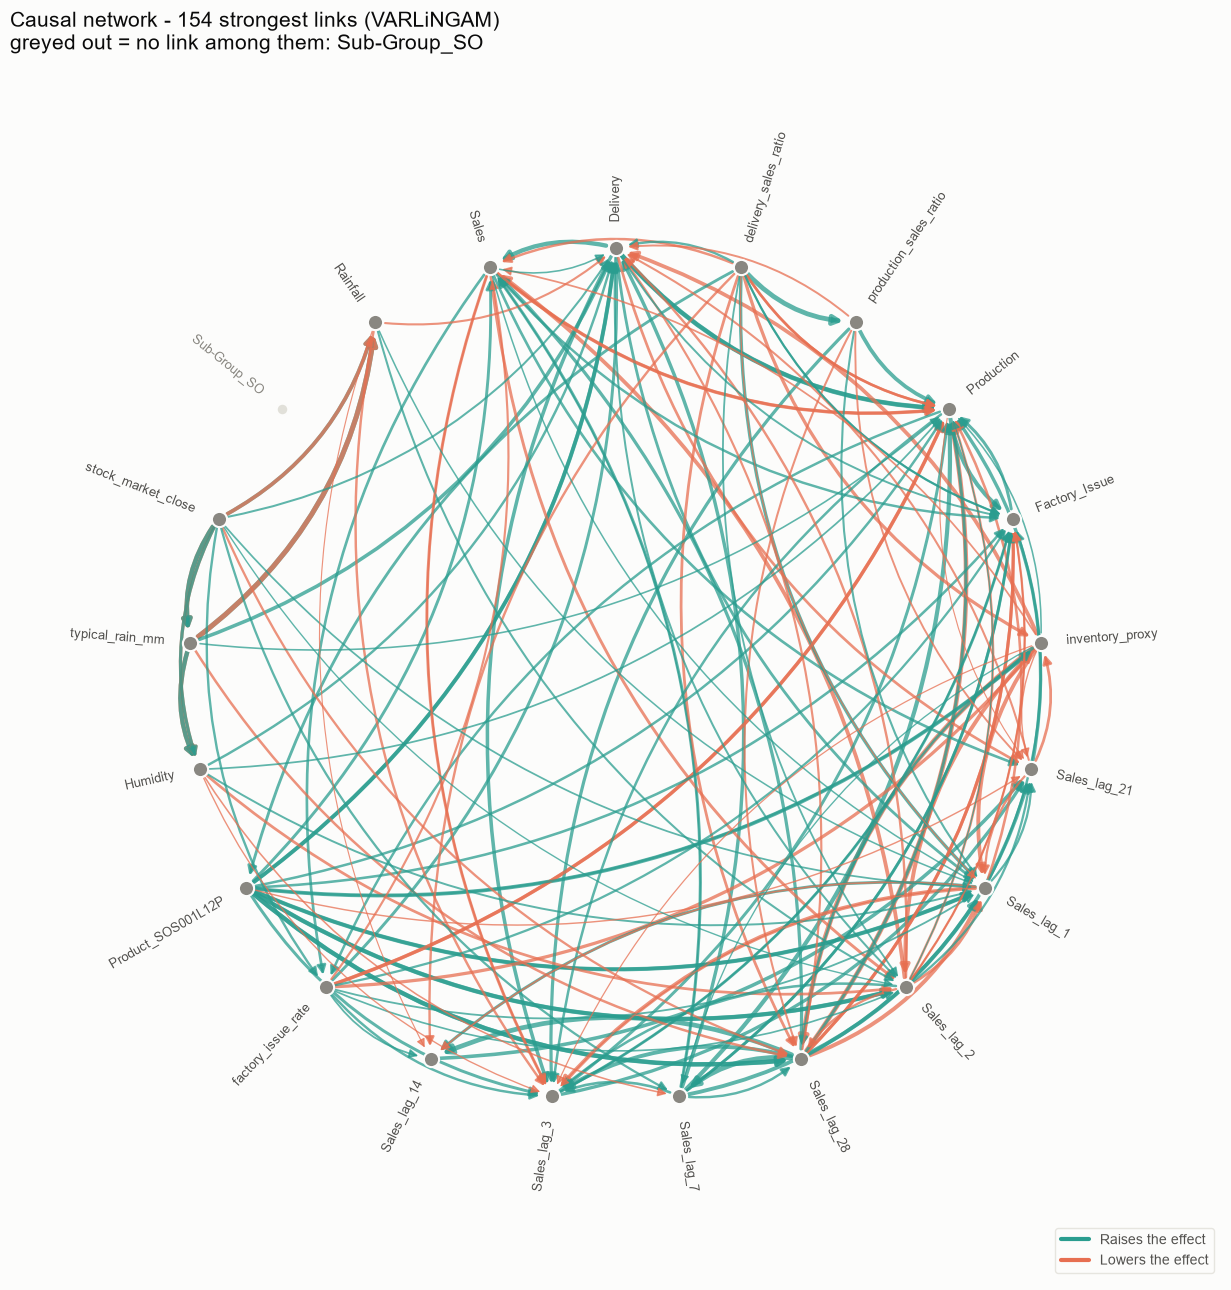

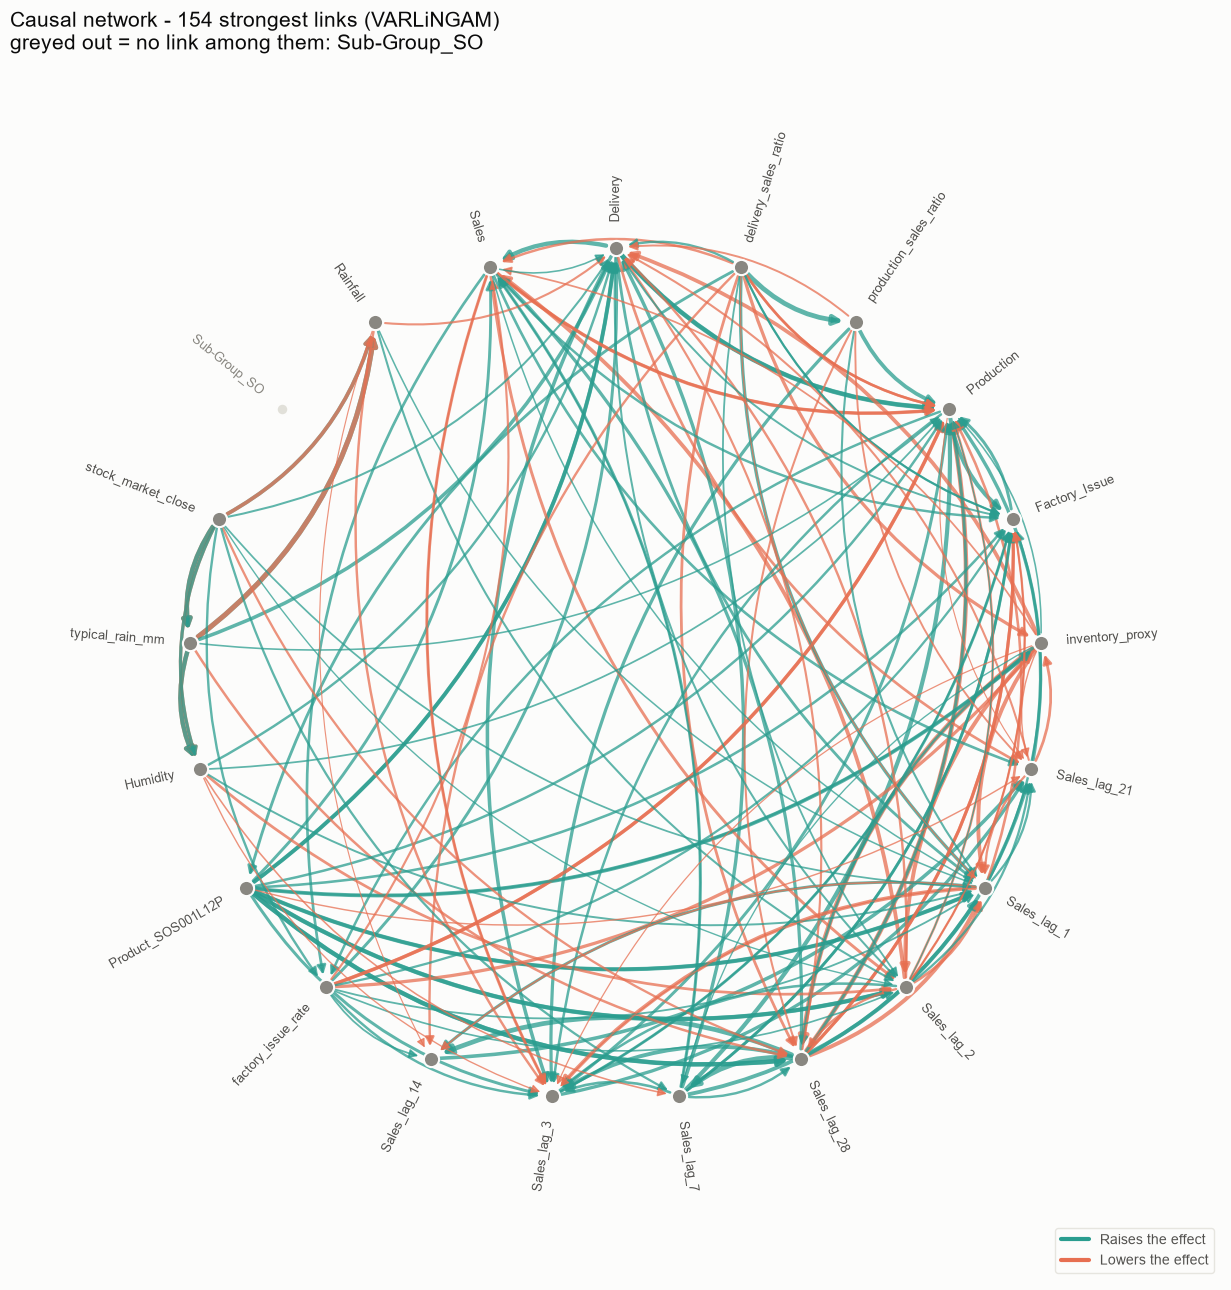

In [13]:
from pathlib import Path

from matplotlib.colors import LinearSegmentedColormap, SymLogNorm
from matplotlib.patches import FancyArrowPatch

CAUSAL_POSITIVE = "#2a9d8f"
CAUSAL_NEGATIVE = "#e76f51"
CAUSAL_SURFACE = "#fcfcfb"
CAUSAL_INK = "#52514e"
CAUSAL_MUTED = "#898781"
CAUSAL_GRID = "#e1e0d9"



# Diverging ramp built from the same two poles as the charts above, through a
# neutral grey midpoint so "no effect" reads as nothing.
CAUSAL_CMAP = LinearSegmentedColormap.from_list(
    "causal_diverging", [CAUSAL_NEGATIVE, "#f0efec", CAUSAL_POSITIVE]
)


def _save_causal_figure(fig, save_path):
    """Write a causal figure to disk, creating the folder if it is missing.

    Called before `plt.show()`: the inline backend detaches the figure from pyplot
    once it has been displayed, so saving afterwards is fragile.
    """
    if fig is None or save_path is None:
        return
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"Saved plot -> {save_path}")


def _causal_variables(edges, variables=None):
    """Every node that should appear, isolated ones included."""
    if variables is not None:
        return list(variables)
    if "variables" in edges.attrs:
        return list(edges.attrs["variables"])
    names = pd.concat([edges["cause"], edges["effect"]]).dropna().unique()
    return sorted(names)


def _causal_links(edges, min_abs=0.0):
    """The real links only - isolated placeholder rows and dust dropped."""
    links = edges.loc[edges["effect"].notna() & (edges["coefficient"].abs() > min_abs)].copy()
    links["magnitude"] = links["coefficient"].abs()
    return links


def plot_causal_matrix(edges, variables=None, min_abs=0.0, title=None, save_path=None):
    """Show the whole graph as one cause x effect matrix per lag.

    Every modelled variable gets a row and a column, so a variable with no links at
    all is still visible - as an empty row and column. A blank cell means no edge;
    colour means an edge, its hue the sign and its intensity the strength.

    Coefficients here span many orders of magnitude, so the colour scale is
    symmetric-log: `min_abs` (or a small fraction of the largest coefficient) is the
    point below which everything reads as neutral.
    """
    names = _causal_variables(edges, variables)
    links = _causal_links(edges, min_abs=min_abs)
    if links.empty:
        print("No causal edges left to plot.")
        return None

    lags = sorted(links["lag"].dropna().unique())
    index = {name: position for position, name in enumerate(names)}

    grids = []
    for lag in lags:
        grid = np.full((len(names), len(names)), np.nan)   # NaN = no edge at all
        for row in links.loc[links["lag"] == lag].itertuples():
            if row.cause in index and row.effect in index:
                grid[index[row.cause], index[row.effect]] = row.coefficient
        grids.append(grid)

    extreme = links["magnitude"].max()
    threshold = min_abs if min_abs > 0 else max(extreme * 1e-6, np.finfo(float).tiny)
    norm = SymLogNorm(linthresh=threshold, vmin=-extreme, vmax=extreme, base=10)
    cmap = CAUSAL_CMAP.copy()
    cmap.set_bad(CAUSAL_SURFACE)

    # One panel per lag, stacked vertically: a notebook scrolls down, so three
    # side-by-side matrices would only shrink the labels past readability.
    cell = max(0.34, min(0.55, 12.0 / len(names)))
    panel = cell * len(names)
    width, height = panel + 4.2, (panel + 1.9) * len(lags) + 1.2
    fig, axes = plt.subplots(len(lags), 1, figsize=(width, height), squeeze=False)
    axes = axes[:, 0]
    fig.patch.set_facecolor(CAUSAL_SURFACE)
    # Margins in inches, not fractions: a tall stacked figure would otherwise get
    # inches of dead space wherever a default fractional margin applies.
    fig.subplots_adjust(top=1 - 1.1 / height, bottom=1.3 / height,
                        left=2.0 / width, right=1 - 0.3 / width,
                        hspace=1.8 / panel)

    for column, (lag, grid) in enumerate(zip(lags, grids)):
        ax = axes[column]
        image = ax.imshow(grid, cmap=cmap, norm=norm, aspect="equal")
        ax.set_facecolor(CAUSAL_SURFACE)
        ax.set_xticks(range(len(names)))
        ax.set_xticklabels(names, rotation=45, ha="right", fontsize=9, color=CAUSAL_INK)
        ax.set_title("cause and effect on the same day" if lag == 0
                     else f"cause at t-{lag}, effect at t",
                     fontsize=13, color=CAUSAL_INK, pad=8, loc="left")
        ax.set_xlabel("effect", fontsize=11, color=CAUSAL_INK)
        ax.set_yticks(range(len(names)))
        ax.set_yticklabels(names, fontsize=9, color=CAUSAL_INK)
        ax.set_ylabel("cause", fontsize=11, color=CAUSAL_INK)
        # Hairline separators instead of borders around each cell.
        ax.set_xticks(np.arange(-0.5, len(names), 1), minor=True)
        ax.set_yticks(np.arange(-0.5, len(names), 1), minor=True)
        ax.grid(which="minor", color=CAUSAL_GRID, linewidth=0.5)
        ax.grid(which="major", visible=False)
        ax.tick_params(which="minor", length=0)
        ax.tick_params(which="major", length=0, colors=CAUSAL_MUTED)
        for spine in ax.spines.values():
            spine.set_color(CAUSAL_GRID)

    bar = fig.colorbar(image, ax=list(axes), fraction=0.03, pad=0.03,
                       ticks=[-extreme, -threshold, 0, threshold, extreme])
    bar.set_label("coefficient  (blank = no edge)", color=CAUSAL_INK, fontsize=11)
    bar.ax.set_yticklabels([f"{-extreme:.1e}", f"{-threshold:.0e}", "0",
                            f"{threshold:.0e}", f"{extreme:.1e}"],
                           fontsize=9, color=CAUSAL_INK)
    bar.outline.set_edgecolor(CAUSAL_GRID)

    isolated = [name for name in names
                if name not in set(links["cause"]) | set(links["effect"])]
    heading = title or "Causal graph, every variable on every other (VARLiNGAM)"
    if isolated:
        heading += f"\n{len(isolated)} variable(s) with no link: {', '.join(isolated)}"
    fig.suptitle(heading, color="#0b0b0b", fontsize=15, x=0.01, ha="left",
                 y=1 - 0.25 / height, va="top")

    _save_causal_figure(fig, save_path)
    plt.show()
    return fig


def plot_causal_network(edges, variables=None, top_n=30, min_abs=0.0, title=None,
                        save_path=None):
    """Node-link view of the full graph, limited to the `top_n` strongest links.

    Every variable sits on the ring, so one with no link at all is still on the
    picture - just with nothing attached to it, and greyed out. Arrows run from cause
    to effect, curving clockwise so that A->B and B->A stay apart; colour is the sign
    and width the strength. A loop on a node is a variable acting on its own past.
    """
    names = _causal_variables(edges, variables)
    links = _causal_links(edges, min_abs=min_abs).nlargest(top_n, "magnitude")
    if links.empty:
        print("No causal edges left to plot.")
        return None

    linked = set(links["cause"]) | set(links["effect"])
    angles = {name: np.pi / 2 - 2 * np.pi * position / len(names)
              for position, name in enumerate(names)}
    positions = {name: np.array([np.cos(angle), np.sin(angle)])
                 for name, angle in angles.items()}

    fig, ax = plt.subplots(figsize=(13, 13))
    fig.patch.set_facecolor(CAUSAL_SURFACE)
    ax.set_facecolor(CAUSAL_SURFACE)

    log_magnitude = np.log10(links["magnitude"])
    lo, hi = log_magnitude.min(), log_magnitude.max()
    weights = (np.full(len(links), 1.0) if hi == lo
               else (log_magnitude - lo) / (hi - lo))

    for row, weight in zip(links.itertuples(), weights):
        color = CAUSAL_POSITIVE if row.coefficient >= 0 else CAUSAL_NEGATIVE
        width = 0.8 + 2.8 * weight
        start, end = positions[row.cause], positions[row.effect]
        if row.cause == row.effect:
            # Self-link: a small loop hanging outside the ring at that node.
            outward = start / np.linalg.norm(start)
            sideways = np.array([-outward[1], outward[0]]) * 0.035
            ax.add_patch(FancyArrowPatch(
                tuple(start + outward * 0.05 + sideways),
                tuple(start + outward * 0.05 - sideways),
                arrowstyle="-|>", mutation_scale=11, linewidth=width, color=color,
                alpha=0.85, shrinkA=0, shrinkB=0, zorder=2,
                connectionstyle="arc3,rad=3.0",
            ))
        else:
            # arc3's rad is relative to the start -> end direction, so the two
            # directions of the same pair bow to opposite sides on their own.
            ax.add_patch(FancyArrowPatch(
                tuple(start), tuple(end),
                arrowstyle="-|>", mutation_scale=13, linewidth=width, color=color,
                alpha=0.75, shrinkA=7, shrinkB=9, zorder=2,
                connectionstyle="arc3,rad=0.22",
            ))

    for name in names:
        attached = name in linked
        x, y = positions[name]
        ax.scatter([x], [y], s=120 if attached else 70,
                   color=CAUSAL_MUTED if attached else CAUSAL_GRID,
                   edgecolors=CAUSAL_SURFACE, linewidths=1.5, zorder=3)

        # Labels radiate outward, flipped on the left half so none read upside down.
        angle = np.degrees(angles[name]) % 360
        on_the_right = angle <= 90 or angle >= 270
        rotation = angle if on_the_right else angle - 180
        label_xy = positions[name] * 1.06
        ax.text(label_xy[0], label_xy[1], name, fontsize=9.5, rotation=rotation,
                rotation_mode="anchor", ha="left" if on_the_right else "right",
                va="center", zorder=4,
                color=CAUSAL_INK if attached else CAUSAL_MUTED)

    unlinked = [name for name in names if name not in linked]
    heading = title or f"Causal network - {len(links)} strongest links (VARLiNGAM)"
    if unlinked:
        heading += f"\ngreyed out = no link among them: {', '.join(unlinked)}"
    ax.set_title(heading, color="#0b0b0b", pad=14, loc="left", fontsize=15)

    ax.set_xlim(-1.42, 1.42)
    ax.set_ylim(-1.42, 1.42)
    ax.set_aspect("equal")
    ax.axis("off")

    handles = [
        plt.Line2D([], [], color=CAUSAL_POSITIVE, linewidth=3),
        plt.Line2D([], [], color=CAUSAL_NEGATIVE, linewidth=3),
    ]
    legend = ax.legend(handles, ["Raises the effect", "Lowers the effect"],
                       loc="lower right", frameon=True, facecolor=CAUSAL_SURFACE,
                       edgecolor=CAUSAL_GRID, fontsize=10)
    for text in legend.get_texts():
        text.set_color(CAUSAL_INK)

    plt.tight_layout()
    _save_causal_figure(fig, save_path)
    plt.show()
    return fig


# The full graph: every variable on every other one, not only what reaches Sales.
# standardize=True puts all coefficients in standard-deviation units - without it a
# link out of Sales (thousands) would dwarf one out of a rate (~0.01) on units alone.
# min_abs cuts the numerical dust VARLiNGAM leaves in the matrix.
causal_lag = 1

causal_edges_all = get_causal_edges(
    feature_data=date_example[cols],
    target=date_example["Sales"],
    lag=causal_lag,
    target_name="Sales",
    target_only=False,
    standardize=True,
    min_abs=0.05,
)

# remove Reflexive edge
causal_edges_all = causal_edges_all[causal_edges_all["cause"] != causal_edges_all["effect"]]

print(f"{len(causal_edges_all)} rows | "
      f"{(causal_edges_all['direction'] != 'none').sum()} links | "
      f"{(causal_edges_all['direction'] == 'none').sum()} variable(s) with no link")

display(causal_edges_all)

# One folder per analysis window, so a re-run on a different window does not
# overwrite the previous one. The lag goes in the filename because it is the
# parameter most likely to change between runs of the same window.
causality_dir = Path(f"../../causality/causality_{start_date}_{end_date}")
causality_dir.mkdir(parents=True, exist_ok=True)
plot_stem = f"lag{causal_lag}_from_{start_date}_to_{end_date}"

plot_causal_matrix(
    causal_edges_all,
    min_abs=0.05,
    save_path=causality_dir / f"causal_matrix_{plot_stem}.png",
)
plot_causal_network(
    causal_edges_all,
    top_n=1000,  # min_abs=0.05
    save_path=causality_dir / f"causal_network_{plot_stem}.png",
)


In [14]:
import pandas as pd
import os
from datetime import datetime

# 1. Assume you have your data in pandas DataFrames (replace these with your actual data)
# df_causality = ... 
# df_feature_importance = ...

# 2. Get the current date and time, formatted cleanly for filenames
# Format: YYYY-MM-DD_HH-MM-SS
current_time = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# 3. Define your target directories
# causality_dir = "../../causality"
# fi_dir = "../../feature_importance"

# fi_dir = Path(f"../../feature_importance/feature_importance_{start_date}_{end_date}")
# fi_dir.mkdir(parents=True, exist_ok=True)

# 5. Define the full file paths
# causality_filepath = os.path.join(causality_dir, f"causality_from_{start_date}_to_{end_date}-{current_time}.csv")
# fi_filepath = os.path.join(fi_dir, f"feature_importance_from_{start_date}_to_{end_date}-{current_time}.csv")
causality_filepath = os.path.join(causality_dir, f"causality_from_{start_date}_to_{end_date}.csv")
fi_filepath = os.path.join(fi_dir, f"feature_importance_from_{start_date}_to_{end_date}.csv")


# 6. Export the dataframes to CSV
causal_edges_all.to_csv(causality_filepath, index=False)
shap_feature_importance.to_csv(fi_filepath, index=False)

print(f"Successfully saved:\n - {causality_filepath}\n - {fi_filepath}")

Successfully saved:
 - ..\..\causality\causality_2023-08-02_2023-08-09\causality_from_2023-08-02_to_2023-08-09.csv
 - ..\..\feature_importance\feature_importance_2023-08-02_2023-08-09\feature_importance_from_2023-08-02_to_2023-08-09.csv
